**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
library(gghalves)
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



## Prepare

**Set global variable**

In [2]:
vec = c(
    "fcc_astarr_macs_input_overlap",
    "fcc_astarr_macs_input_union"
)
names(vec) = vec

VEC_TXT_FOLDER = vec
for(txt in vec){cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


In [3]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    ### set file directory
    txt_fdiry  = file.path(FD_RES, "analysis_fcc_comparison", txt_folder)
    txt_fname = "region.annotation.fcc_starrmpra_group.coverage.crispri.v2.tsv"
    txt_fpath = file.path(txt_fdiry, txt_fname)

    ### read table
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})

### assign and show
lst_dat_region_fcc_import = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
head(dat, 3)

$fcc_astarr_macs_input_overlap
[1] 76706    13

$fcc_astarr_macs_input_union
[1] 84792    13



Chrom,ChromStart,ChromEnd,Region,Distance2TSS,TSS_Proximity,TSS,Direction_Assay,Group,Assay_Group_CRISPR,Assay_Label_CRISPR,Assay_Score_CRISPR,Assay_Annot_CRISPR
<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>
chr1,605104,605675,chr1:605104-605675,23335,Distal,0,Inactive,Distal:Inactive,CRISPRi-Growth,CRISPRi-Growth,0.0904152,Screen:Signif
chr1,778233,779389,chr1:778233-779389,0,Proximal,1,Active,Proximal:Active,CRISPRi-Growth,CRISPRi-Growth,0.1162065,Screen:NotSignif
chr1,817031,817525,chr1:817031-817525,0,Proximal,1,Inactive,Proximal:Inactive,CRISPRi-Growth,CRISPRi-Growth,-0.2753540,Screen:NotSignif


In [4]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    ### set file directory
    txt_fdiry = file.path(FD_RES, "region_annotation", txt_folder, "summary")
    txt_fname = "region.annotation.hic_intact_deep.loop.score.node.tsv"
    txt_fpath = file.path(txt_fdiry, txt_fname)

    ### read table
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})
names(lst) = VEC_TXT_FOLDER

### assign and show
lst_dat_region_hic_import = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 53760    11

$fcc_astarr_macs_input_union
[1] 65084    11



Chrom,ChromStart,ChromEnd,Region,Loop_Count,Loop_Score_Mean,Loop_Score_Sum,Loop_Zcore_Global_Mean,Loop_Zcore_Global_Sum,Loop_Zcore_DistSm_Mean,Loop_Zcore_DistSm_Sum
chr1,778233,779389,chr1:778233-779389,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,826796,828040,chr1:826796-828040,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,869637,870233,chr1:869637-870233,4,1.938149,7.752596,0.3837763,1.5351050,-0.1816422,-0.7265690


In [5]:
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    dat_region_fcc = lst_dat_region_fcc_import[[txt_folder]]
    dat_region_hic = lst_dat_region_hic_import[[txt_folder]]

    vec = c("Chrom", "ChromStart", "ChromEnd", "Region")
    dat = dplyr::inner_join(
        dat_region_fcc,
        dat_region_hic,
        by = vec
    )
    return(dat)
})

lst_dat_region_merge = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 45169    20

$fcc_astarr_macs_input_union
[1] 47756    20



Chrom,ChromStart,ChromEnd,Region,Distance2TSS,TSS_Proximity,TSS,Direction_Assay,Group,Assay_Group_CRISPR,Assay_Label_CRISPR,Assay_Score_CRISPR,Assay_Annot_CRISPR,Loop_Count,Loop_Score_Mean,Loop_Score_Sum,Loop_Zcore_Global_Mean,Loop_Zcore_Global_Sum,Loop_Zcore_DistSm_Mean,Loop_Zcore_DistSm_Sum
chr1,778233,779389,chr1:778233-779389,0,Proximal,1,Active,Proximal:Active,CRISPRi-Growth,CRISPRi-Growth,0.1162065,Screen:NotSignif,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,826796,828040,chr1:826796-828040,0,Proximal,1,Inactive,Proximal:Inactive,CRISPRi-Growth,CRISPRi-Growth,-0.1634086,Screen:Signif,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,869637,870233,chr1:869637-870233,6570,Distal,0,Inactive,Distal:Inactive,CRISPRi-Growth,CRISPRi-Growth,-0.1121624,Screen:NotSignif,4,1.938149,7.752596,0.3837763,1.5351050,-0.1816422,-0.7265690


In [6]:
lst = lst_dat_region_merge
dat = lst[[1]]
any(is.na(dat))

[1] FALSE

In [7]:
### set text size
theme_text = theme(
    title      = element_text(size = 16),
    axis.title = element_text(size = 16),
    axis.text  = element_text(size = 16),
    #legend.title = element_text(size = 16),
    legend.title = element_blank(),
    legend.text  = element_text(size = 16)
)

In [8]:
idx_region = "fcc_astarr_macs_input_overlap"

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment
  purposes.”


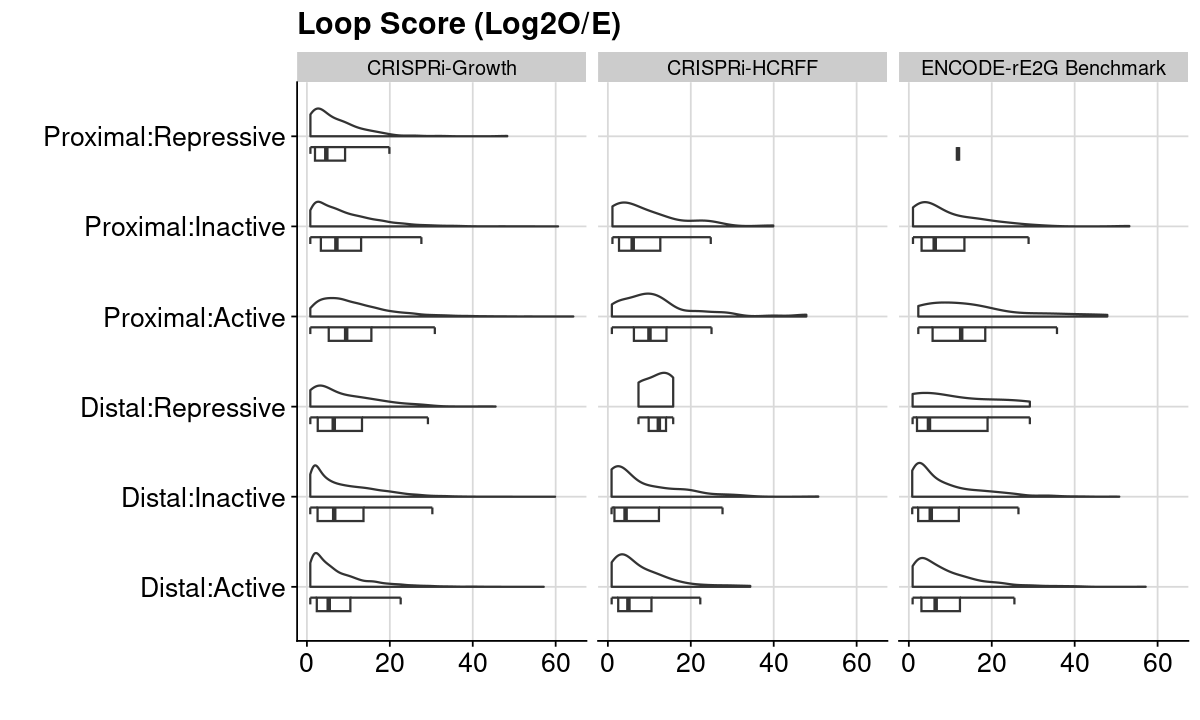

In [14]:
lst = lst_dat_region_merge
lst = lapply(lst, function(dat){
    #dat = dat %>% dplyr::filter(Group == "Proximal:Repressive", Assay_Label_CRISPR == "CRISPRi-HCRFF")
    #dat = dat %>% dplyr::filter(Group == "Proximal:Repressive", Assay_Label_CRISPR == "ENCODE-rE2G Benchmark")
    
    gpt = ggplot(dat, aes(x=Group, y=Loop_Score_Sum)) +
        geom_half_violin(side = "r", trim = TRUE, alpha = 0.4, adjust = 1.2) +
        geom_half_boxplot(side = "l", width = 0.3, position = position_nudge(x = -0.12), outlier.shape = NA) +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score (Log2O/E)", x = "", y = "") +
        coord_flip() +
        theme_text +
        facet_wrap(~Assay_Label_CRISPR)
})

gpt = lst[[idx_region]]
gpt_export_loop_score = gpt
options(repr.plot.height=6, repr.plot.width=10)
print(gpt)

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment
  purposes.”


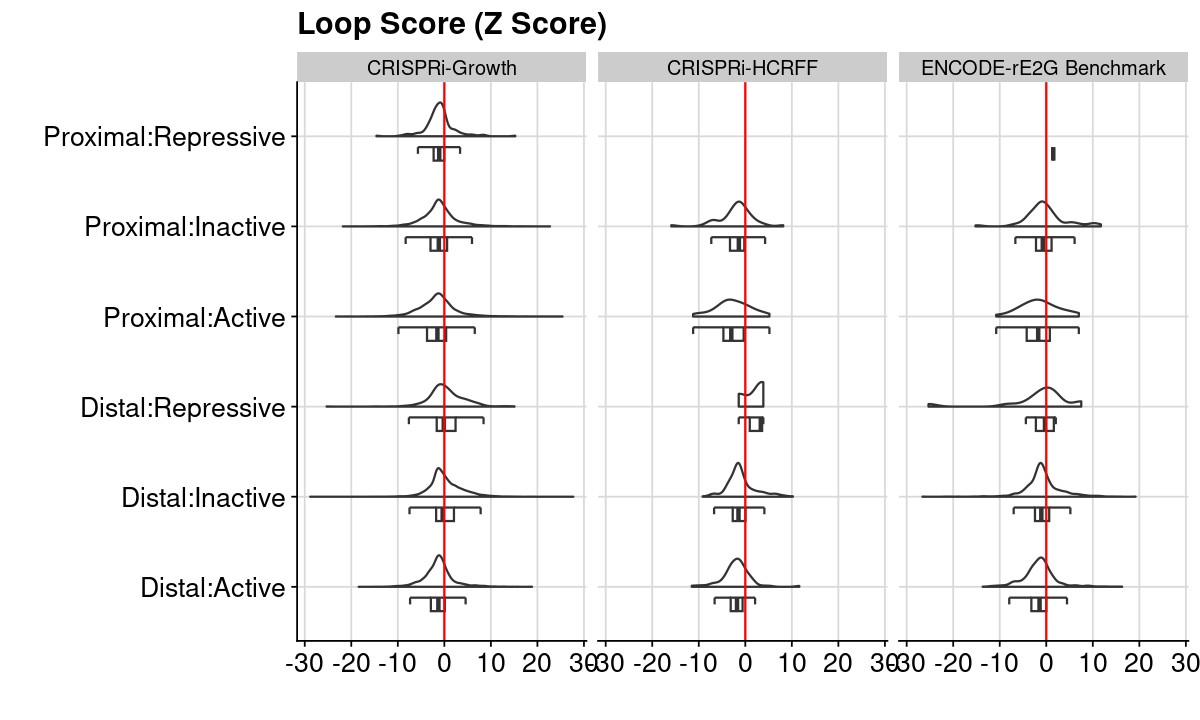

In [15]:
lst = lst_dat_region_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Group, y=Loop_Zcore_DistSm_Sum)) +
        geom_half_violin(side = "r", trim = TRUE, alpha = 0.4, adjust = 1.2) +
        geom_half_boxplot(side = "l", width = 0.3, position = position_nudge(x = -0.12), outlier.shape = NA) +
        geom_hline(yintercept = 0, color = "red") +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score (Z Score)", x = "", y = "") +
        coord_flip() +
        theme_text +
        facet_wrap(~Assay_Label_CRISPR)
})

gpt = lst[[idx_region]]
gpt_export_loop_score = gpt
options(repr.plot.height=6, repr.plot.width=10)
print(gpt)

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment
  purposes.”


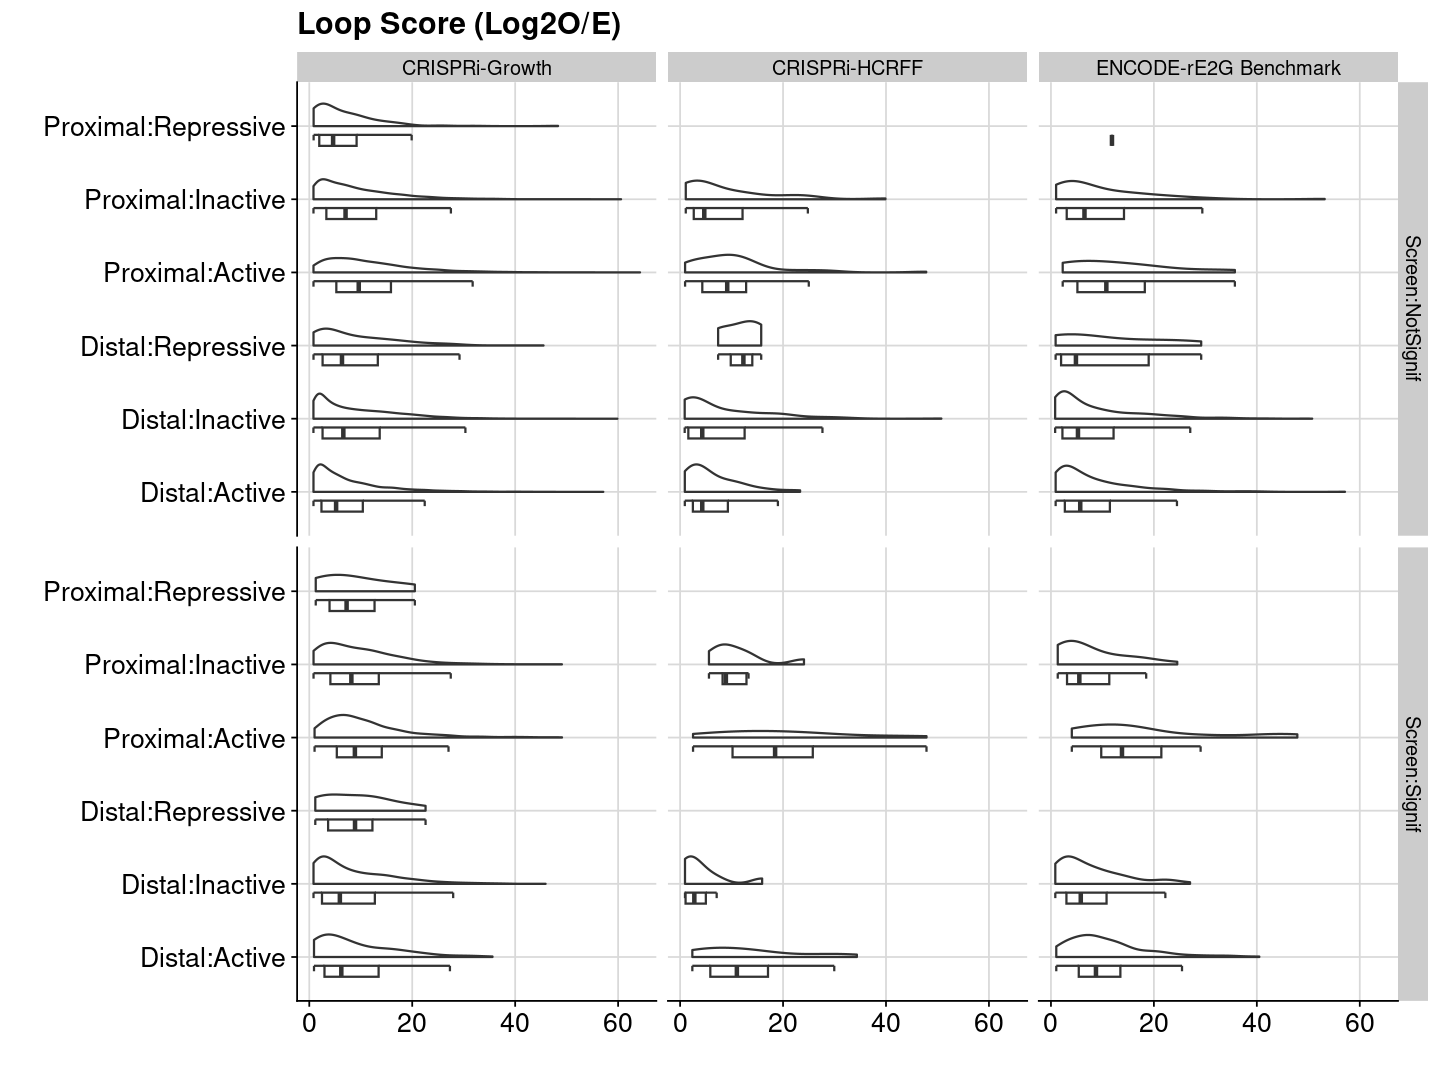

In [24]:
lst = lst_dat_region_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Group, y=Loop_Score_Sum)) +
        geom_half_violin(side = "r", trim = TRUE, alpha = 0.4, adjust = 1.2) +
        geom_half_boxplot(side = "l", width = 0.3, position = position_nudge(x = -0.12), outlier.shape = NA) +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score (Log2O/E)", x = "", y = "") +
        coord_flip() +
        theme_text +
        facet_grid(Assay_Annot_CRISPR ~ Assay_Label_CRISPR)
})

gpt = lst[[idx_region]]
gpt_export_loop_score = gpt
options(repr.plot.height=9, repr.plot.width=12)
print(gpt)

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment
  purposes.”


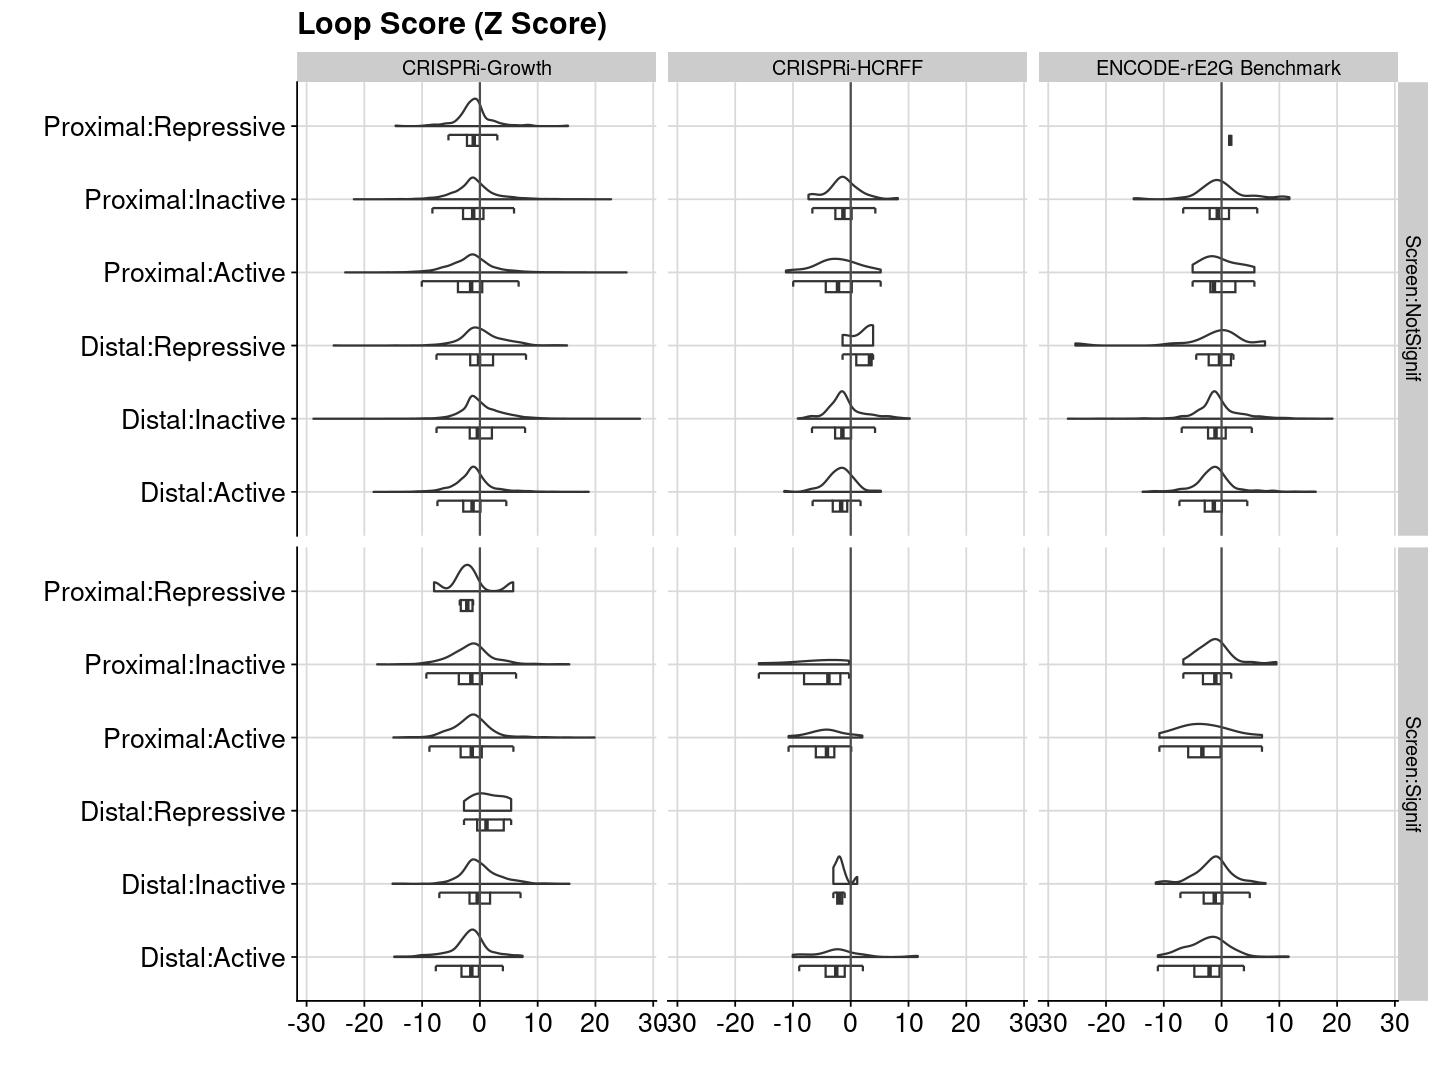

In [23]:
lst = lst_dat_region_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Group, y=Loop_Zcore_DistSm_Sum)) +
        geom_half_violin(side = "r", trim = TRUE, alpha = 0.4, adjust = 1.2) +
        geom_half_boxplot(side = "l", width = 0.3, position = position_nudge(x = -0.12), outlier.shape = NA) +
        geom_hline(yintercept = 0, color = "grey30") +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score (Z Score)", x = "", y = "") +
        coord_flip() +
        theme_text +
        facet_grid(Assay_Annot_CRISPR ~ Assay_Label_CRISPR)
})

gpt = lst[[idx_region]]
gpt_export_loop_score = gpt
options(repr.plot.height=9, repr.plot.width=12)
print(gpt)

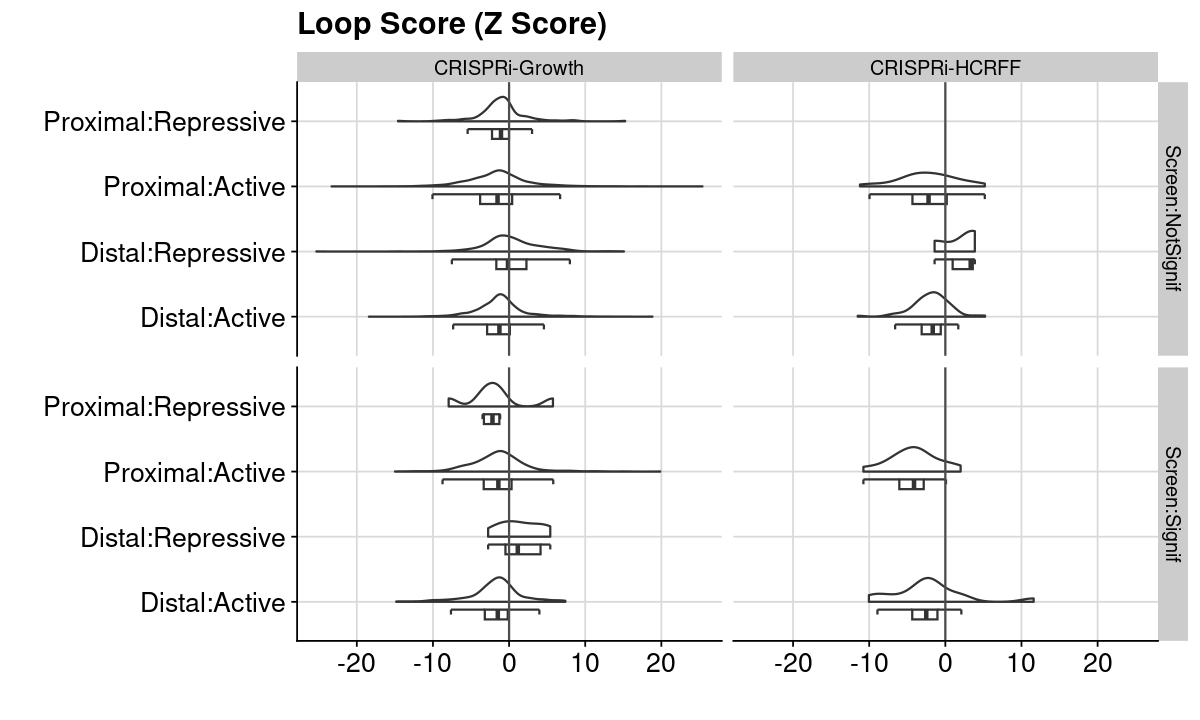

In [39]:
lst = lst_dat_region_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Group, y=Loop_Zcore_DistSm_Sum)) +
        geom_half_violin(side = "r", trim = TRUE, alpha = 0.4, adjust = 1.2) +
        geom_half_boxplot(side = "l", width = 0.3, position = position_nudge(x = -0.12), outlier.shape = NA) +
        geom_hline(yintercept = 0, color = "grey30") +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score (Z Score)", x = "", y = "") +
        coord_flip() +
        theme_text +
        facet_grid(Label~Assay_Group)
})

gpt = lst[[idx_region]]
gpt_export_loop_score = gpt
options(repr.plot.height=6, repr.plot.width=10)
print(gpt)